# 04b. Comparison Analysis

**Owner:** Member A
**Step 11 (joint), part 2:** explain the test results from `04a_test_results.ipynb`. Are the differences between the Random Forest, Logistic Regression and the persistence score larger than chance, and why do the two algorithms behave differently?

**Inputs.** This notebook reads only saved result files: the test predictions and metrics from `04a`, and the cross-validation and validation results from the two model notebooks. No model is refitted and the test years are not scored again.

**Colours used throughout:** Random Forest orange, Logistic Regression blue, persistence score green, persistence grey.

In [1]:
import json
import sys
from pathlib import Path

# Make the project root importable so the shared `src` modules work from notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score, brier_score_loss, cohen_kappa_score

from src import config, viz

viz.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

M = config.METRICS_DIR
predictions = pd.read_csv(M / "test_predictions.csv")
test_metrics = pd.read_csv(M / "test_metrics.csv", index_col=0)
with open(M / "test_final_models.json") as f:
    final_models = json.load(f)

y = predictions["target"].to_numpy()
SCORES = {"Random Forest": predictions["rf_score"].to_numpy(),
          "Logistic Regression": predictions["lr_score"].to_numpy(),
          "Persistence score": predictions["cases_rel_threshold"].to_numpy()}
WARNINGS = {"Random Forest": predictions["rf_warning"].to_numpy(),
            "Logistic Regression": predictions["lr_warning"].to_numpy(),
            "Persistence": predictions["outbreak_now"].to_numpy()}
COLOURS = {"Random Forest": viz.ORANGE, "Logistic Regression": viz.BLUE,
           "Persistence score": viz.AQUA, "Persistence": viz.TEXT_MUTED}
print(f"Test weeks: {len(predictions):,}   Outbreak weeks: {int(y.sum())}   Districts: {predictions[config.DISTRICT_COL].nunique()}")

Test weeks: 3,825   Outbreak weeks: 367   Districts: 25


## 1. The same comparison in three periods

The models have now been scored in three separate periods: the five cross-validation years used for tuning (2016 to 2020), the validation years (2021 to 2022) and the test years (2023 to 2025). PR-AUC cannot be compared across periods, because the outbreak rate differs, but the gap between each model and the persistence score in the same period can.

In [2]:
def cv_threshold_means(path, model):
    t = pd.read_csv(M / path)
    return t[t["model"] == model][["F1", "MCC"]].mean()

rf_cv = pd.read_csv(M / "rf_cv_by_year.csv", index_col=0)
lr_cv = pd.read_csv(M / "lr_cv_by_year.csv", index_col=0)
rf_val = pd.read_csv(M / "rf_validation_metrics.csv", index_col=0)
lr_val = pd.read_csv(M / "lr_validation_metrics.csv", index_col=0)

rows = []
for period in ["CV 2016-2020", "Validation 2021-2022", "Test 2023-2025"]:
    for name in ["Random Forest", "Logistic Regression", "Persistence score"]:
        if period.startswith("CV"):
            pr = {"Random Forest": rf_cv.loc["Random Forest, tuned", "mean"],
                  "Logistic Regression": lr_cv.loc["Logistic Regression, tuned", "mean"],
                  "Persistence score": rf_cv.loc["Persistence score", "mean"]}[name]
            source = {"Random Forest": ("rf_cv_threshold_metrics.csv", "Random Forest, tuned"),
                      "Logistic Regression": ("lr_cv_threshold_metrics.csv", "Logistic Regression, tuned"),
                      "Persistence score": ("rf_cv_threshold_metrics.csv", "Persistence")}[name]
            f1, mcc = cv_threshold_means(*source)
        elif period.startswith("Validation"):
            row = {"Random Forest": rf_val.loc["Random Forest, tuned"],
                   "Logistic Regression": lr_val.loc["Logistic Regression, tuned"],
                   "Persistence score": rf_val.loc["Persistence score"]}[name]
            pr, f1, mcc = row["PR-AUC"], row["F1"], row["MCC"]
        else:
            row = test_metrics.loc[name]
            pr, f1, mcc = row["PR-AUC"], row["F1"], row["MCC"]
        rows.append({"period": period, "model": name, "PR-AUC": pr, "F1": f1, "MCC": mcc})
periods = pd.DataFrame(rows)
for metric in ["PR-AUC", "F1", "MCC"]:
    base = periods[periods["model"] == "Persistence score"].set_index("period")[metric]
    periods[f"{metric} gain over persistence score"] = periods[metric] - periods["period"].map(base)
periods.pivot_table(index="model", columns="period", values=["PR-AUC", "PR-AUC gain over persistence score"],
                    sort=False).round(3)

PR-AUC                                     PR-AUC gain over persistence score                                    
period              CV 2016-2020 Validation 2021-2022 Test 2023-2025                       CV 2016-2020 Validation 2021-2022 Test 2023-2025
model                                                                                                                                      
Random Forest              0.711                0.538          0.603                              0.024               -0.015          0.027
Logistic Regression        0.696                0.585          0.595                              0.009                0.032          0.019
Persistence score          0.687                0.554          0.576                              0.000                0.000          0.000

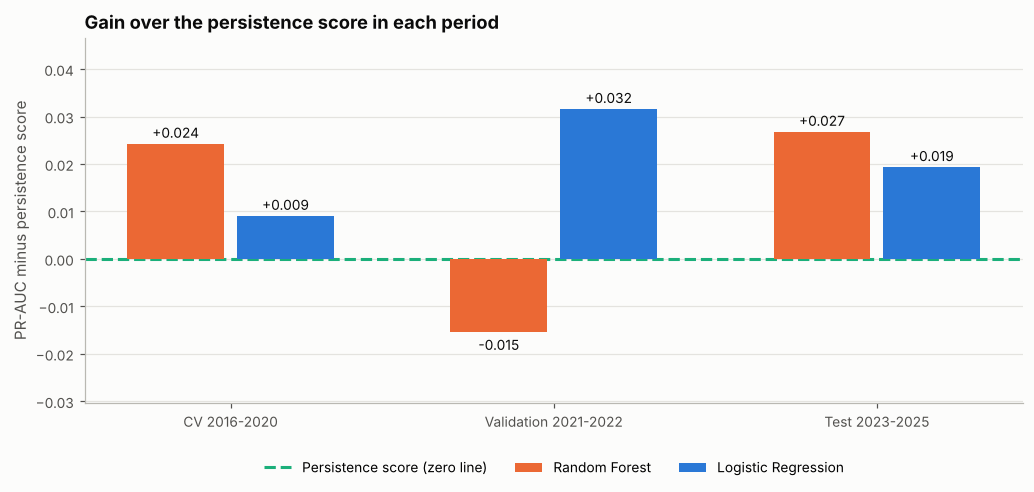

In [3]:
order = ["CV 2016-2020", "Validation 2021-2022", "Test 2023-2025"]
gain = periods[periods["model"] != "Persistence score"].pivot_table(
    index="period", columns="model", values="PR-AUC gain over persistence score", sort=False).loc[order]

fig, ax = plt.subplots(figsize=(9.5, 4.6))
x = np.arange(len(order))
width = 0.34
for offset, name in [(-width / 2, "Random Forest"), (width / 2, "Logistic Regression")]:
    bars = ax.bar(x + offset, gain[name], width=width - 0.04, color=COLOURS[name], label=name, zorder=2)
    for bar, value in zip(bars, gain[name]):
        ax.annotate(f"{value:+.3f}", (bar.get_x() + bar.get_width() / 2, value),
                    textcoords="offset points", xytext=(0, 4 if value >= 0 else -12),
                    ha="center", fontsize=9, color=viz.TEXT)
ax.axhline(0, color=COLOURS["Persistence score"], linewidth=2, linestyle="--", zorder=1,
           label="Persistence score (zero line)")
ax.set_xticks(x, order)
ax.set_ylabel("PR-AUC minus persistence score")
ax.set_title("Gain over the persistence score in each period")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
low, high = gain.min().min(), gain.max().max()
ax.set_ylim(min(low, 0) - 0.015, high + 0.015)
fig.tight_layout()
viz.save(fig, "cmp_01_gain_by_period")
plt.show()

**Finding.** Both models beat the persistence score in most periods, but by small margins, and the order of the two models changes from period to period.

- **Logistic Regression** is ahead of the persistence score in all three periods: +0.009 in cross-validation, +0.032 on validation and +0.019 on test.
- **The Random Forest** has the larger gain in cross-validation (+0.024) and on test (+0.027), but fell below the persistence score on 2021 to 2022 (-0.015).

The forest's gains are larger when they appear, while Logistic Regression's are steadier. In no period is either model more than 0.032 above the persistence score, which confirms that most of the forecasting skill comes from the current case level that the persistence score already uses.

At the chosen thresholds the gains are smaller still. F1 for both models was slightly below persistence in cross-validation and validation, and above it only on the test years (`cmp_periods.csv`). Section 2 tests whether the test gains are real.

## 2. Are the test differences larger than chance?

Weeks within a district are strongly linked, so treating 3,825 weeks as independent would overstate the certainty. Instead, whole districts are resampled with replacement, 2,000 times, and every difference is recomputed on each resample. A difference is convincing when its 95% interval excludes zero.

Three measures are compared: PR-AUC (ranking), recall (share of outbreak weeks warned at the chosen threshold) and F1 (balance of precision and recall at the threshold). For PR-AUC the baseline is the persistence score; for recall and F1 it is persistence, whose yes or no warnings are identical to the persistence score at its threshold.

In [4]:
def f1_recall(target, warning):
    tp = np.sum((warning == 1) & (target == 1))
    fp = np.sum((warning == 1) & (target == 0))
    fn = np.sum((warning == 0) & (target == 1))
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return f1, recall

def measures(idx):
    t = y[idx]
    out = {f"PR-AUC: {name}": average_precision_score(t, s[idx]) for name, s in SCORES.items()}
    for name, w in WARNINGS.items():
        out[f"F1: {name}"], out[f"recall: {name}"] = f1_recall(t, w[idx])
    return out

COMPARISONS = [
    ("PR-AUC", "Random Forest", "Logistic Regression"),
    ("PR-AUC", "Random Forest", "Persistence score"),
    ("PR-AUC", "Logistic Regression", "Persistence score"),
    ("recall", "Random Forest", "Logistic Regression"),
    ("recall", "Random Forest", "Persistence"),
    ("recall", "Logistic Regression", "Persistence"),
    ("F1", "Random Forest", "Logistic Regression"),
    ("F1", "Random Forest", "Persistence"),
    ("F1", "Logistic Regression", "Persistence"),
]

district_rows = [np.flatnonzero(predictions[config.DISTRICT_COL].to_numpy() == d)
                 for d in predictions[config.DISTRICT_COL].unique()]
observed = measures(np.arange(len(y)))
rng = np.random.default_rng(config.RANDOM_SEED)
samples = []
for _ in range(2000):
    idx = np.concatenate([district_rows[i] for i in rng.integers(0, len(district_rows), len(district_rows))])
    if y[idx].sum() == 0:
        continue
    samples.append(measures(idx))
samples = pd.DataFrame(samples)

rows = []
for metric, a, b in COMPARISONS:
    diff = samples[f"{metric}: {a}"] - samples[f"{metric}: {b}"]
    low, high = np.percentile(diff, [2.5, 97.5])
    rows.append({"measure": metric, "comparison": f"{a} minus {b}",
                 "observed difference": observed[f"{metric}: {a}"] - observed[f"{metric}: {b}"],
                 "95% interval low": low, "95% interval high": high,
                 "share of resamples above zero": float(np.mean(diff > 0)),
                 "interval excludes zero": bool(low > 0 or high < 0)})
bootstrap = pd.DataFrame(rows)
print(f"Resamples used: {len(samples)}")
bootstrap

Resamples used: 2000


,measure,comparison,observed difference,95% interval low,95% interval high,share of resamples above zero,interval excludes zero
0,PR-AUC,Random Forest minus Logistic Regression,0.007,-0.033,0.045,0.615,False
1,PR-AUC,Random Forest minus Persistence score,0.027,-0.010,0.061,0.928,False
2,PR-AUC,Logistic Regression minus Persistence score,0.019,0.002,0.035,0.986,True
3,recall,Random Forest minus Logistic Regression,-0.025,-0.060,0.010,0.073,False
4,recall,Random Forest minus Persistence,0.068,0.040,0.103,1.000,True
5,recall,Logistic Regression minus Persistence,0.093,0.050,0.135,1.000,True
6,F1,Random Forest minus Logistic Regression,-0.005,-0.034,0.020,0.366,False
7,F1,Random Forest minus Persistence,0.014,-0.012,0.039,0.853,False
8,F1,Logistic Regression minus Persistence,0.018,-0.013,0.049,0.883,False


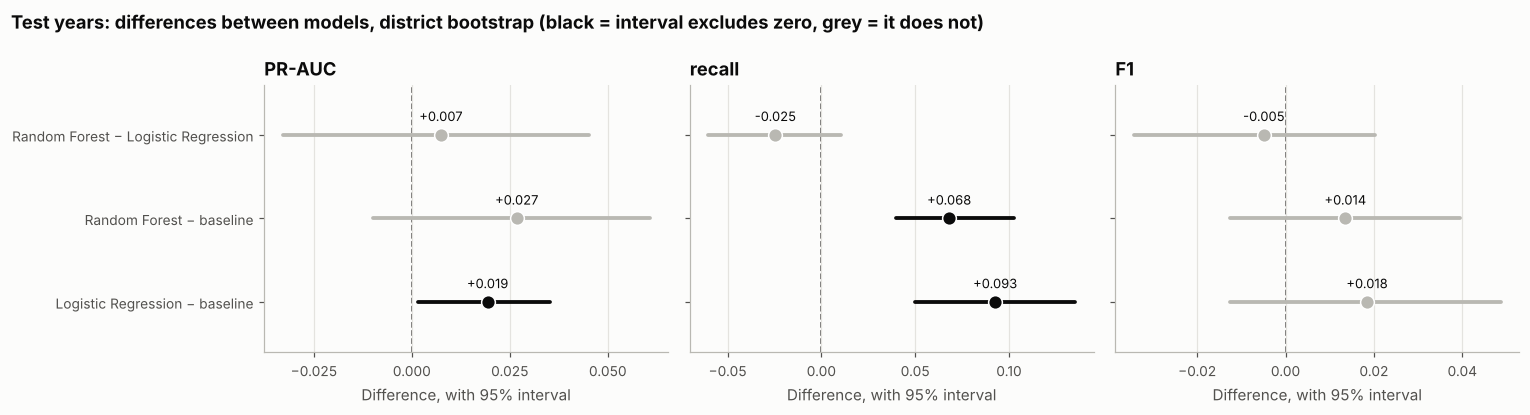

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
labels = ["Random Forest − Logistic Regression", "Random Forest − baseline", "Logistic Regression − baseline"]
for ax, metric in zip(axes, ["PR-AUC", "recall", "F1"]):
    part = bootstrap[bootstrap["measure"] == metric].reset_index(drop=True)
    for i, r in part.iterrows():
        colour = viz.TEXT if r["interval excludes zero"] else viz.NEUTRAL
        ax.plot([r["95% interval low"], r["95% interval high"]], [i, i], color=colour, linewidth=2.5, solid_capstyle="round")
        ax.plot(r["observed difference"], i, "o", color=colour, markersize=9, markeredgecolor="white", zorder=3)
        ax.annotate(f"{r['observed difference']:+.3f}", (r["observed difference"], i), textcoords="offset points",
                    xytext=(0, 9), ha="center", fontsize=8.5, color=viz.TEXT)
    ax.axvline(0, color=viz.TEXT_MUTED, linewidth=1, linestyle="--", zorder=0)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.set_yticks(range(3), labels)
    ax.set_ylim(2.6, -0.6)
    ax.set_title(metric)
    ax.set_xlabel("Difference, with 95% interval")
    ax.grid(axis="y", visible=False)
fig.suptitle("Test years: differences between models, district bootstrap (black = interval excludes zero, grey = it does not)",
             x=0.01, ha="left", fontweight="bold", color=viz.TEXT)
fig.tight_layout()
viz.save(fig, "cmp_02_bootstrap")
plt.show()

**Finding.** Only three of the nine differences are clearly larger than chance.

- **Both models catch more outbreaks than persistence.** Recall rises by 6.8 points for the Random Forest (95% interval 4.0 to 10.3) and by 9.3 points for Logistic Regression (5.0 to 13.5), and all 2,000 resamples agree.
- **Logistic Regression ranks better than the persistence score,** but only just: +0.019 of PR-AUC, with an interval from 0.002 to 0.035. The forest's gain is larger (+0.027) but varies more from district to district, so its interval (-0.010 to +0.061) includes zero. It is ahead in 93% of resamples.
- **Neither model improves F1 convincingly** over persistence (+0.014 and +0.018, both intervals include zero). The extra outbreaks caught are paid for with extra false alarms.

Between the two models nothing is settled. The forest's PR-AUC lead (+0.007) holds in only 61% of resamples, the forest's recall is higher in only 7% of them, and the two F1 values differ by just 0.005. On the test years the two models cannot be told apart statistically.

These nine intervals are not corrected for multiple comparisons. The two recall gains would survive such a correction, because every resample agrees. Logistic Regression's PR-AUC gain, whose interval only just clears zero, might not.

## 3. Onsets and continuing outbreaks

As in step 10, the test weeks are split by the situation the model faces. **Onset weeks** have no outbreak now; the question is whether one starts within two weeks. **Active weeks** are already in outbreak; the question is whether it will still be running in two weeks. Persistence predicts no onsets at all and always predicts that an active outbreak continues.

In [6]:
calm = predictions["outbreak_now"].to_numpy() == 0
rows = []
for situation, mask in [("Onsets (no outbreak now)", calm), ("Continuing (outbreak now)", ~calm)]:
    row = {"situation": situation, "weeks": int(mask.sum()), "positives": int(y[mask].sum()),
           "chance PR-AUC": y[mask].mean()}
    for name, s in SCORES.items():
        row[f"PR-AUC: {name}"] = average_precision_score(y[mask], s[mask])
    for name in ["Random Forest", "Logistic Regression", "Persistence"]:
        row[f"recall: {name}"] = f1_recall(y[mask], WARNINGS[name][mask])[1]
    rows.append(row)
situations = pd.DataFrame(rows).set_index("situation")

# Bootstrap the Random Forest minus Logistic Regression gap within each situation, as in section 2.
gap_rows = []
rng = np.random.default_rng(config.RANDOM_SEED)
for situation, mask in [("Onsets (no outbreak now)", calm), ("Continuing (outbreak now)", ~calm)]:
    diffs = []
    for _ in range(2000):
        idx = np.concatenate([district_rows[i] for i in rng.integers(0, len(district_rows), len(district_rows))])
        idx = idx[mask[idx]]
        if y[idx].sum() == 0 or y[idx].sum() == len(idx):
            continue
        diffs.append(average_precision_score(y[idx], SCORES["Random Forest"][idx])
                     - average_precision_score(y[idx], SCORES["Logistic Regression"][idx]))
    low, high = np.percentile(diffs, [2.5, 97.5])
    gap_rows.append({"situation": situation,
                     "RF minus LR, PR-AUC": situations.loc[situation, "PR-AUC: Random Forest"]
                                            - situations.loc[situation, "PR-AUC: Logistic Regression"],
                     "95% interval low": low, "95% interval high": high})
situation_gaps = pd.DataFrame(gap_rows).set_index("situation")
shown = situations.T.astype(object)
for r in shown.index:
    shown.loc[r] = [f"{int(v):,}" if r in ("weeks", "positives") else f"{v:.3f}" for v in situations[r]]
display(shown)
situation_gaps

situation,Onsets (no outbreak now),Continuing (outbreak now)
weeks,"3,454",371
positives,158,209
chance PR-AUC,0.046,0.563
PR-AUC: Random Forest,0.189,0.796
PR-AUC: Logistic Regression,0.210,0.779
PR-AUC: Persistence score,0.164,0.763
recall: Random Forest,0.184,0.981
recall: Logistic Regression,0.259,0.967
recall: Persistence,0.000,1.000


,"RF minus LR, PR-AUC",95% interval low,95% interval high
situation,,,
Onsets (no outbreak now),-0.020,-0.090,0.033
Continuing (outbreak now),0.017,-0.041,0.081


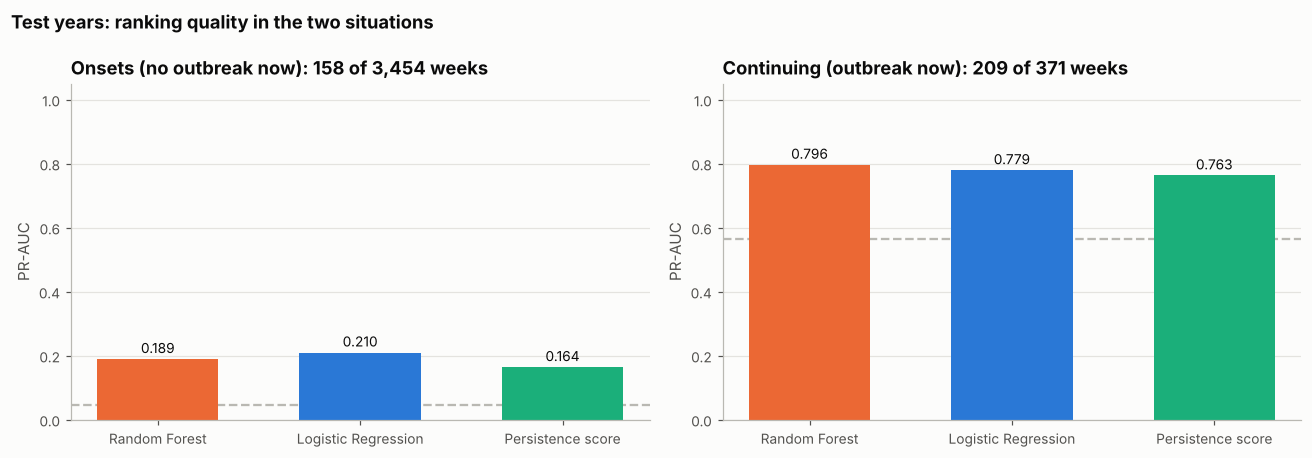

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, situation in zip(axes, situations.index):
    names = list(SCORES)
    values = [situations.loc[situation, f"PR-AUC: {n}"] for n in names]
    bars = ax.bar(range(3), values, color=[COLOURS[n] for n in names], width=0.6, zorder=2)
    for bar, value in zip(bars, values):
        ax.annotate(f"{value:.3f}", (bar.get_x() + bar.get_width() / 2, value), textcoords="offset points",
                    xytext=(0, 4), ha="center", fontsize=9, color=viz.TEXT)
    chance = situations.loc[situation, "chance PR-AUC"]
    ax.axhline(chance, color=viz.NEUTRAL, linestyle="--", linewidth=1.5, zorder=1)
    ax.annotate(f"chance {chance:.3f}", (2.45, chance), textcoords="offset points", xytext=(0, 4),
                ha="right", fontsize=8.5, color=viz.TEXT_MUTED)
    ax.set_xticks(range(3), names)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("PR-AUC")
    ax.set_title(f"{situation}: {situations.loc[situation, 'positives']} of {situations.loc[situation, 'weeks']:,} weeks")
    ax.grid(axis="x", visible=False)
fig.suptitle("Test years: ranking quality in the two situations", x=0.01, ha="left", fontweight="bold", color=viz.TEXT)
fig.tight_layout()
viz.save(fig, "cmp_03_onsets_continuing")
plt.show()

**Finding.** The split shows where each model earns its gain.

- **Onsets:** Logistic Regression ranks best, with PR-AUC 0.210 against 0.189 for the forest, 0.164 for the persistence score and 0.046 for chance. At its threshold it warns of 41 of the 158 onsets (26%), against 29 (18%) for the forest. Persistence cannot warn of any.
- **Continuing outbreaks:** the order reverses. The forest scores 0.796, Logistic Regression 0.779 and the persistence score 0.763, with chance at 0.563. Persistence warns of all 209 continuing outbreak weeks; the forest misses 4 of them and Logistic Regression 7.

So the models' extra catches over persistence (section 2) all come from onsets. The forest gives up 4 continuing weeks to gain 29 onsets, and Logistic Regression gives up 7 to gain 41.

Within each situation the gap between the two models lies inside the bootstrap noise (onsets -0.020, interval -0.090 to +0.033; continuing +0.017, interval -0.041 to +0.081). What gives the pattern weight is that it repeats. Logistic Regression also ranked onsets above the forest in cross-validation (0.257 against 0.233) and on validation (0.173 against 0.140), and the forest also ranked continuing outbreaks higher in cross-validation (0.852 against 0.836), as reported in the two model notebooks.

## 4. Do the two models make the same mistakes?

If both models read essentially the same signal, they will catch and miss the same outbreak weeks. The tables count outbreak weeks and false alarms by which model warned, and measure how similarly the two models rank all test weeks. The last table describes the outbreak weeks that neither model warned of.

In [8]:
rf_w, lr_w = WARNINGS["Random Forest"], WARNINGS["Logistic Regression"]
outbreak, quiet = y == 1, y == 0

def overlap(mask):
    return pd.Series({
        "both models warned": int(np.sum(mask & (rf_w == 1) & (lr_w == 1))),
        "Random Forest only": int(np.sum(mask & (rf_w == 1) & (lr_w == 0))),
        "Logistic Regression only": int(np.sum(mask & (rf_w == 0) & (lr_w == 1))),
        "neither warned": int(np.sum(mask & (rf_w == 0) & (lr_w == 0))),
    })

error_overlap = pd.DataFrame({
    "outbreak weeks (warning = caught)": overlap(outbreak),
    "weeks without outbreak (warning = false alarm)": overlap(quiet),
    "outbreak weeks that were onsets": overlap(outbreak & calm),
})
agreement = pd.Series({
    "warnings agree (share of all weeks)": float(np.mean(rf_w == lr_w)),
    "Cohen's kappa between the two sets of warnings": cohen_kappa_score(rf_w, lr_w),
    "Spearman rank correlation of the scores": spearmanr(SCORES["Random Forest"], SCORES["Logistic Regression"])[0],
    "Spearman correlation, forest vs persistence score": spearmanr(SCORES["Random Forest"], SCORES["Persistence score"])[0],
    "Spearman correlation, logistic vs persistence score": spearmanr(SCORES["Logistic Regression"], SCORES["Persistence score"])[0],
}, name="value")
display(error_overlap)
agreement.to_frame()

,outbreak weeks (warning = caught),weeks without outbreak (warning = false alarm),outbreak weeks that were onsets
both models warned,215,160,17
Random Forest only,19,46,12
Logistic Regression only,28,61,24
neither warned,105,3191,105


,value
warnings agree (share of all weeks),0.960
Cohen's kappa between the two sets of warnings,0.807
Spearman rank correlation of the scores,0.832
"Spearman correlation, forest vs persistence score",0.899
"Spearman correlation, logistic vs persistence score",0.882


In [9]:
# The outbreak weeks that neither model warned of: what did the forecast week look like?
missed = outbreak & (rf_w == 0) & (lr_w == 0)
rel_now = predictions["cases_rel_threshold"].to_numpy()
missed_summary = pd.Series({
    "outbreak weeks missed by both models": f"{int(missed.sum())}",
    "of which onsets (no outbreak at the forecast week)": f"{int(np.sum(missed & calm))}",
    "median cases at forecast, share of threshold": f"{np.median(rel_now[missed]):.2f}",
    "median score (threshold), Random Forest":
        f"{np.median(SCORES['Random Forest'][missed]):.3f} ({final_models['models']['Random Forest']['decision_threshold']:.3f})",
    "median score (threshold), Logistic Regression":
        f"{np.median(SCORES['Logistic Regression'][missed]):.3f} ({final_models['models']['Logistic Regression']['decision_threshold']:.3f})",
}, name="value")
missed_summary.to_frame()

,value
outbreak weeks missed by both models,105
of which onsets (no outbreak at the forecast week),105
"median cases at forecast, share of threshold",0.52
"median score (threshold), Random Forest",0.050 (0.323)
"median score (threshold), Logistic Regression",0.064 (0.242)


**Finding.** The two models mostly agree. Their warnings match in 96% of test weeks (Cohen's kappa 0.81), and their scores order the weeks similarly (Spearman 0.83). Each model is even closer to the persistence score (0.90 for the forest, 0.88 for Logistic Regression) than to the other model. Both are built on the same case signal and differ mainly in how they depart from it.

Of the 367 outbreak weeks, both models caught 215, the forest alone 19 and Logistic Regression alone 28. Most of these single catches are onsets: 12 of the forest's 19 and 24 of Logistic Regression's 28. Logistic Regression also raises more false alarms of its own (61 against 46).

All 105 outbreak weeks missed by both models are onsets. At the forecast week these districts stood at a median of about half their outbreak threshold (0.52), and the models gave them median risks of 0.050 and 0.064, far below their warning thresholds of 0.323 and 0.242. These outbreaks gave little sign in the case counts two weeks ahead. No algorithm can recover a signal that its inputs do not contain, so a different algorithm alone is unlikely to catch them.

## 5. Can the scores be read as probabilities?

A public-health team would act on a stated risk, so it matters whether a predicted 30% means an outbreak follows about 30% of the time. The test weeks are grouped by predicted score, and the average prediction in each group is compared with the share that turned into outbreaks. Points on the diagonal mean well calibrated scores. The Brier score summarises calibration and sharpness together (lower is better).

In [10]:
EDGES = [0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0001]
rows = []
for name in ["Random Forest", "Logistic Regression"]:
    s = SCORES[name]
    groups = pd.cut(s, EDGES, right=False)
    table = pd.DataFrame({"score": s, "target": y, "group": groups}).groupby("group", observed=True).agg(
        weeks=("target", "size"), mean_prediction=("score", "mean"), observed_rate=("target", "mean"))
    table = table.reset_index().assign(model=name)
    rows.append(table)
calibration = pd.concat(rows, ignore_index=True)
calibration_summary = pd.DataFrame({
    name: {"Brier score": brier_score_loss(y, SCORES[name]),
           "mean predicted risk": SCORES[name].mean(),
           "actual outbreak rate": y.mean()}
    for name in ["Random Forest", "Logistic Regression"]}).T
calibration_summary

,Brier score,mean predicted risk,actual outbreak rate
Random Forest,0.056,0.108,0.096
Logistic Regression,0.056,0.105,0.096


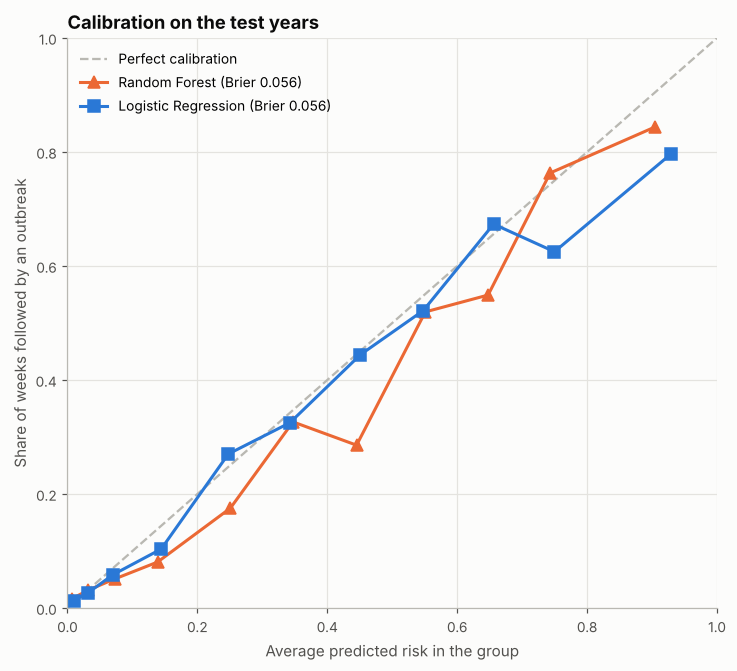

In [11]:
fig, ax = plt.subplots(figsize=(6.8, 6.2))
ax.plot([0, 1], [0, 1], color=viz.NEUTRAL, linestyle="--", linewidth=1.5, label="Perfect calibration")
for name, marker in [("Random Forest", "^"), ("Logistic Regression", "s")]:
    part = calibration[(calibration["model"] == name) & (calibration["weeks"] >= 20)]
    ax.plot(part["mean_prediction"], part["observed_rate"], color=COLOURS[name], marker=marker, markersize=8,
            linewidth=2, label=f"{name} (Brier {calibration_summary.loc[name, 'Brier score']:.3f})")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Average predicted risk in the group",
       ylabel="Share of weeks followed by an outbreak")
ax.set_title("Calibration on the test years")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
viz.save(fig, "cmp_04_calibration")
plt.show()

**Finding.** Both models give usable probabilities, and overall they are equally good. Their Brier scores are almost identical (0.0563 and 0.0565). Both predict slightly more risk than occurred: an average of 10.8% for the forest and 10.5% for Logistic Regression, against an actual outbreak rate of 9.6%.

They differ in where they go wrong.

- **Middle range, 0.1 to 0.7:** Logistic Regression's points sit close to the diagonal. The forest's mostly fall below it, so its middle scores overstate the risk. For example, the 63 weeks it scored between 0.4 and 0.5 (average 0.45) were followed by an outbreak only 29% of the time.
- **Top group, 0.8 and above:** both overstate the risk, Logistic Regression more so. Its 108 weeks in this group had an average prediction of 0.93, but only 80% turned into outbreaks. The forest's 96 weeks averaged 0.90, and 84% turned into outbreaks.

Each group above 0.4 holds only 32 to 108 weeks, so single points can move noticeably by chance. For a health team, the practical reading is that a Logistic Regression score above 0.8 means roughly four chances in five, not near certainty.

## 6. Why the algorithms behave differently

Both models lean mostly on one input, `cases_rel_threshold`: this week's cases divided by the district's outbreak threshold. Plotting each model's predicted risk against that input shows how each algorithm turns it into a risk. Every dot is a test week; the line is the average prediction within narrow bands of the input; the grey markers show how often an outbreak actually followed. The vertical line at 1.0 marks the outbreak threshold itself. A second table checks the top of the curves: the weeks far above the threshold, and each model's most confident warnings.

- A **Random Forest** can only predict values that its trees' leaves contain, and every split is a yes or no threshold on one input. Its response should rise in steps, staying flat between split points.
- **Logistic Regression** passes a weighted sum of the (log-transformed) inputs through the sigmoid, so its response must be a smooth S-shaped curve, rising steadily as cases climb.

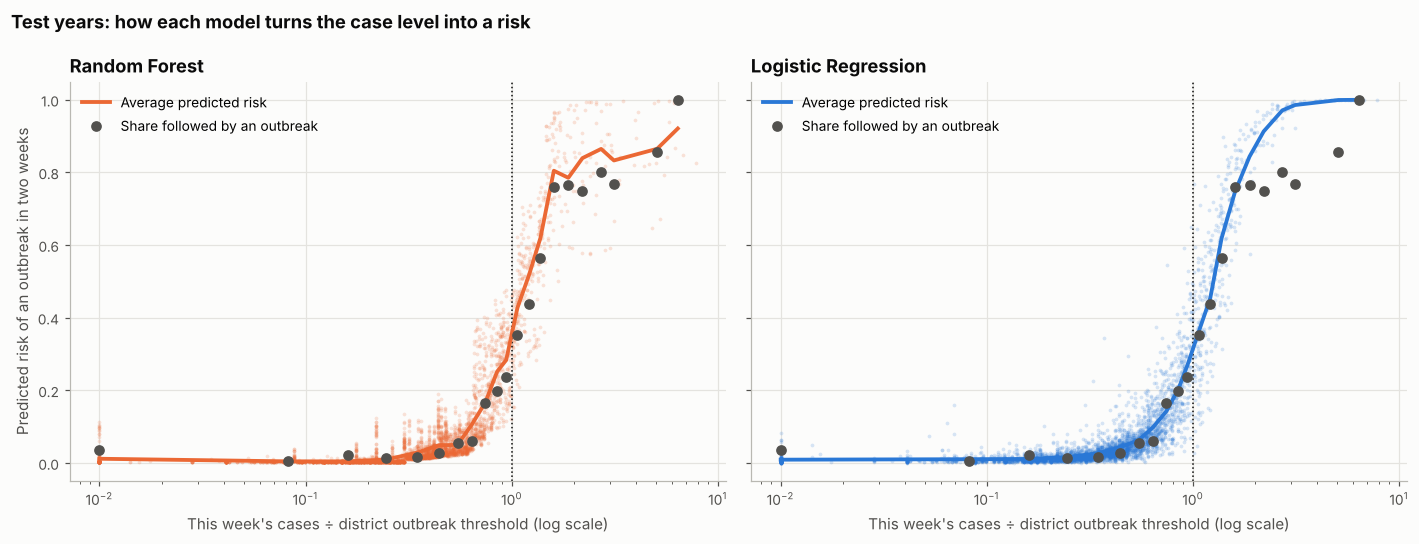

Distinct predicted values on the test weeks: {'Random Forest': 3281, 'Logistic Regression': 3748}


,weeks,rel_median,observed_rate,rf_mean,lr_mean
band,,,,,
"[0.0, 0.05)",197,0.000,0.036,0.012,0.009
"[0.05, 0.1)",179,0.082,0.006,0.005,0.011
"[0.1, 0.2)",526,0.160,0.021,0.005,0.011
"[0.2, 0.3)",541,0.246,0.013,0.010,0.016
"[0.3, 0.4)",553,0.349,0.016,0.029,0.027
"[0.4, 0.5)",505,0.444,0.028,0.049,0.044
"[0.5, 0.6)",289,0.546,0.055,0.050,0.063
"[0.6, 0.7)",265,0.642,0.060,0.106,0.099
"[0.7, 0.8)",180,0.745,0.167,0.167,0.143


In [12]:
BANDS = [0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.15, 1.3, 1.5, 1.75, 2, 2.5, 3, 4, 6, np.inf]
rel = predictions["cases_rel_threshold"].to_numpy()
band = pd.cut(rel, BANDS, right=False)
by_band = pd.DataFrame({"rel": rel, "target": y, "band": band,
                        "Random Forest": SCORES["Random Forest"], "Logistic Regression": SCORES["Logistic Regression"]}
                       ).groupby("band", observed=True).agg(
    weeks=("target", "size"), rel_median=("rel", "median"), observed_rate=("target", "mean"),
    rf_mean=("Random Forest", "mean"), lr_mean=("Logistic Regression", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
x_plot = np.clip(rel, 0.01, None)
for ax, (name, column) in zip(axes, [("Random Forest", "rf_mean"), ("Logistic Regression", "lr_mean")]):
    ax.scatter(x_plot, SCORES[name], s=6, alpha=0.18, color=COLOURS[name], linewidths=0, zorder=1)
    ax.plot(np.clip(by_band["rel_median"], 0.01, None), by_band[column], color=COLOURS[name], linewidth=2.5,
            zorder=3, label="Average predicted risk")
    ax.plot(np.clip(by_band["rel_median"], 0.01, None), by_band["observed_rate"], "o", color=viz.TEXT_MUTED,
            markersize=6, zorder=4, label="Share followed by an outbreak")
    ax.axvline(1.0, color=viz.TEXT, linewidth=1, linestyle=":", zorder=2)
    ax.set_xscale("log")
    ax.set_xlabel("This week's cases ÷ district outbreak threshold (log scale)")
    ax.set_title(name)
    ax.legend(loc="upper left", fontsize=9)
axes[0].set_ylabel("Predicted risk of an outbreak in two weeks")
fig.suptitle("Test years: how each model turns the case level into a risk", x=0.01, ha="left",
             fontweight="bold", color=viz.TEXT)
fig.tight_layout()
viz.save(fig, "cmp_05_response_curves")
plt.show()

distinct = {name: int(np.unique(np.round(SCORES[name], 6)).size) for name in ["Random Forest", "Logistic Regression"]}
print("Distinct predicted values on the test weeks:", distinct)
by_band

In [13]:
# Two checks on the top of the curves: weeks far above the threshold, and each model's most confident warnings.
def top_row(mask):
    return {"weeks": f"{int(mask.sum())}",
            "followed by an outbreak": f"{int(y[mask].sum())} ({y[mask].mean():.0%})",
            "mean score, Random Forest": f"{SCORES['Random Forest'][mask].mean():.3f}",
            "mean score, Logistic Regression": f"{SCORES['Logistic Regression'][mask].mean():.3f}"}

top_end = pd.DataFrame({
    "weeks at least twice the threshold": top_row(rel >= 2.0),
    "Random Forest score of 0.95 or more": top_row(SCORES["Random Forest"] >= 0.95),
    "Logistic Regression score of 0.95 or more": top_row(SCORES["Logistic Regression"] >= 0.95),
}).T
top_end

,weeks,followed by an outbreak,"mean score, Random Forest","mean score, Logistic Regression"
weeks at least twice the threshold,72,58 (81%),0.855,0.962
Random Forest score of 0.95 or more,28,26 (93%),0.980,0.923
Logistic Regression score of 0.95 or more,52,45 (87%),0.879,0.988


**Finding.** The curves match how each algorithm works, and they explain the results of sections 3 and 5.

- **Shared shape.** Both models keep the risk at a few percent until cases reach about 60% of the threshold, then rise steeply through it. This is the case signal the persistence score already captures, which is why the two models agree so closely (section 4).
- **Top of the curve.** Above about 1.5 times the threshold the forest's average levels off at roughly 0.8 to 0.9, a little above the observed share, which mostly lies between 0.75 and 0.86. Each forest prediction is an average of outbreak rates in leaves of at least 50 similar training weeks. Some outbreaks in those weeks ended within two weeks, so the forest cannot become more certain than history allows. Logistic Regression has no such ceiling: its log odds keep growing with the case level, and the sigmoid pushes its risk towards 1. Of the 72 test weeks at least twice the threshold, 81% were followed by an outbreak; the forest predicted 0.855 on average and Logistic Regression 0.962. This is the overconfidence seen in section 5.
- **Most confident warnings.** Logistic Regression gives a score of 0.95 or more to 52 weeks, of which 87% were followed by an outbreak. The forest gives such a score to only 28 weeks, and 93% of them were followed. In the chart the forest's high scores remain spread out, while Logistic Regression's crowd against 1, where they can no longer be ranked against each other. This fits the forest's lead on continuing outbreaks.
- **Below the threshold.** The forest's average rises in steps. Between 0.4 and 0.6 times the threshold it stays at 0.05, then doubles to 0.11 in the next band, whereas Logistic Regression rises smoothly (0.044, 0.063, 0.099). The forest also gives identical scores to more weeks: 3,281 distinct values across the 3,825 test weeks, against 3,748. A smooth response keeps separating weeks as cases creep up towards the threshold, which is where onsets begin. This is a likely reason for Logistic Regression's better onset ranking in all three periods, although the test years alone cannot prove it.

## 7. Practical comparison

Beyond accuracy, a model has to be trained, tuned, explained and trusted. The table collects these properties from the earlier notebooks.

In [14]:
rf_imp = pd.read_csv(M / "rf_feature_importance.csv", index_col=0)["permutation: drop in PR-AUC"]
lr_coef = pd.read_csv(M / "lr_coefficients.csv", index_col=0)
top = lambda s: ", ".join(f"{k} ({v:.3f})" for k, v in s.sort_values(ascending=False).head(3).items())

practical = pd.DataFrame({
    "Random Forest": {
        "hyperparameters tuned": "4 (depth, leaf size, inputs per split, class weight)",
        "settings tried in tuning": f"{len(pd.read_csv(M / 'rf_tuning_results.csv'))} (x 5 folds = {5 * len(pd.read_csv(M / 'rf_tuning_results.csv'))} fits)",
        "training time on 2007-2022 (s)": f"{final_models['models']['Random Forest']['fit_seconds']:.2f}",
        "how it can be explained": "permutation and impurity importance; no direction of effect",
        "top inputs (permutation importance, 2021-2022)": top(rf_imp),
        "Brier score, test": f"{calibration_summary.loc['Random Forest', 'Brier score']:.4f}",
        "PR-AUC, test": round(test_metrics.loc["Random Forest", "PR-AUC"], 3),
        "outbreak weeks warned, test": f"{int(test_metrics.loc['Random Forest', 'TP'])} of {int(y.sum())}",
    },
    "Logistic Regression": {
        "hyperparameters tuned": "2 (regularisation strength C, class weight)",
        "settings tried in tuning": f"{len(pd.read_csv(M / 'lr_tuning_results.csv'))} (x 5 folds = {5 * len(pd.read_csv(M / 'lr_tuning_results.csv'))} fits)",
        "training time on 2007-2022 (s)": f"{final_models['models']['Logistic Regression']['fit_seconds']:.2f}",
        "how it can be explained": "signed coefficients and odds ratios per input, plus permutation importance",
        "top inputs (permutation importance, 2021-2022)": top(lr_coef["permutation: drop in PR-AUC"]),
        "Brier score, test": f"{calibration_summary.loc['Logistic Regression', 'Brier score']:.4f}",
        "PR-AUC, test": round(test_metrics.loc["Logistic Regression", "PR-AUC"], 3),
        "outbreak weeks warned, test": f"{int(test_metrics.loc['Logistic Regression', 'TP'])} of {int(y.sum())}",
    },
})
practical

,Random Forest,Logistic Regression
hyperparameters tuned,"4 (depth, leaf size, inputs per split, class weight)","2 (regularisation strength C, class weight)"
settings tried in tuning,96 (x 5 folds = 480 fits),18 (x 5 folds = 90 fits)
training time on 2007-2022 (s),1.64,0.14
how it can be explained,permutation and impurity importance; no direction of effect,"signed coefficients and odds ratios per input, plus permutation importance"
"top inputs (permutation importance, 2021-2022)","cases_rel_threshold (0.494), humidity_w5_8 (0.019), cases_lag1 (0.016)","cases_rel_threshold (0.547), cases_lag1 (0.142), cases_now (0.090)"
"Brier score, test",0.0563,0.0565
"PR-AUC, test",0.603,0.595
"outbreak weeks warned, test",234 of 367,243 of 367


**Finding.** Logistic Regression is the lighter model in every practical respect: two hyperparameters instead of four, 90 fits in tuning instead of 480, and 0.14 seconds of training against 1.64. Both times are negligible for a forecast issued once a week, so cost does not decide between them at this scale.

Explanation matters more. Logistic Regression's coefficients state the direction and size of each effect, for example that more rainfall raises the odds of an outbreak (`03_model_a_logistic_regression.ipynb`). A public-health team can check such statements against what it knows about dengue. The forest's importance scores say how much an input matters, but not in which direction.

Both models rely mainly on `cases_rel_threshold`. Beyond it, Logistic Regression leans on recent case counts (`cases_lag1`, `cases_now`), while the forest's next inputs, humidity five to eight weeks earlier and last week's cases, matter far less (0.019 and 0.016).

## 8. Conclusion

**Which algorithm forecasts dengue outbreaks better?** On the test years 2023 to 2025 the two perform almost identically. The Random Forest ranks slightly better overall (PR-AUC 0.603 against 0.595), and Logistic Regression catches slightly more outbreaks (243 against 234 of 367). No difference between them survives the district bootstrap.

**What the models add over the baseline.** Both improve on persistence in one clear way: they warn of 7 to 9 more of every 100 outbreak weeks. The gain comes entirely from onsets, which persistence cannot foresee. Their ranking gain over the persistence score is small, 0.019 to 0.027 of PR-AUC. Only Logistic Regression's interval excludes zero, and only narrowly, so it is suggestive rather than proven. Most of the forecasting skill comes from the current case level.

**Where they differ.** Logistic Regression ranks new outbreaks better, and has done so in all three periods. The forest judges better whether an ongoing outbreak will continue, and its most confident warnings are more reliable. Overall calibration is equal, but Logistic Regression's highest scores overstate the risk.

**Recommendation.** For an early warning system we would choose Logistic Regression. The most valuable warnings are the onsets that persistence cannot give, and Logistic Regression catches more of them. Its gain over the persistence score is more consistent across periods, it is simpler to tune, and its coefficients let health staff see why a warning was raised. A score above 0.8 should be read as roughly four chances in five rather than certainty. The Random Forest remains a reasonable choice where the main question is whether current outbreaks will last.

**Limitations**

- The dataset's case counts are below the official national totals in most years: between 53% and 103% of the Epidemiology Unit's annual figures for 2012 to 2020 (`data/README.md`), and the sources are not documented. The comparison between the models is internal to this data and stays valid, but the results may not carry over to the complete official counts.
- The test covers three years and 25 districts, with 367 outbreak weeks and only 158 onsets, so most differences carry wide intervals.
- Two thirds of the onsets (105 of 158) were missed by both models. With case history as the main signal, a warning two weeks ahead of a new outbreak is often not possible from these inputs.
- The outbreak thresholds, the temperature baseline and the district density constant were fitted on 2007 to 2020. In cross-validation they therefore carry information from each fold's validation year and later years, a small leak that makes the cross-validation scores slightly optimistic. The validation and test results are not affected.
- The best settings of both models lie at the edge of their search grids (Random Forest depth 6 and 50 weeks per leaf, Logistic Regression C = 10). The scores around them are flat, so wider grids are unlikely to change much, but this was not tested before the test years were opened.
- The decision thresholds were chosen on cross-validation models trained on fewer years and applied unchanged to the models refitted on 2007 to 2022.
- The decision thresholds maximise F1, which treats a missed outbreak and a false alarm as equally costly. A health authority may weigh them differently.
- The models assume each week's case count is known at the time of the forecast. Reporting delays would shorten the real lead time.
- Both models were trained once on 2007 to 2022 and not updated during the three test years.

**Future work**

- Add cases in neighbouring districts, since an onset in one district may follow rising cases nearby.
- Add data closer to transmission, such as mosquito surveillance indices or changes in the circulating serotype.
- Refit the models each year and recalibrate the scores on the latest validation year, for example with isotonic regression.
- Test a combination of the two models, since each catches outbreak weeks the other misses (19 and 28), and add gradient boosting as a third algorithm.
- Set the decision threshold together with health authorities, based on the relative cost of a missed outbreak and a false alarm.

In [15]:
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
periods.to_csv(M / "cmp_periods.csv", index=False)
bootstrap.to_csv(M / "cmp_bootstrap.csv", index=False)
situations.to_csv(M / "cmp_situations.csv")
situation_gaps.to_csv(M / "cmp_situation_gaps.csv")
error_overlap.to_csv(M / "cmp_error_overlap.csv")
agreement.to_csv(M / "cmp_agreement.csv")
missed_summary.to_csv(M / "cmp_missed_by_both.csv")
calibration.to_csv(M / "cmp_calibration.csv", index=False)
calibration_summary.to_csv(M / "cmp_calibration_summary.csv")
by_band.to_csv(M / "cmp_response_bands.csv")
top_end.to_csv(M / "cmp_top_end.csv")
practical.to_csv(M / "cmp_practical.csv")
print("Saved cmp_* tables to results/metrics/")

Saved cmp_* tables to results/metrics/
